In [4]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from keras.models import Sequential
from keras.layers import LSTM, Dense
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
import matplotlib.pyplot as plt

In [52]:
# Chargement des données
df = pd.read_csv('powerconsumption.csv')
df.head()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Datetime                52416 non-null  object 
 1   Temperature             52416 non-null  float64
 2   Humidity                52416 non-null  float64
 3   WindSpeed               52416 non-null  float64
 4   GeneralDiffuseFlows     52416 non-null  float64
 5   DiffuseFlows            52416 non-null  float64
 6   PowerConsumption_Zone1  52416 non-null  float64
 7   PowerConsumption_Zone2  52416 non-null  float64
 8   PowerConsumption_Zone3  52416 non-null  float64
dtypes: float64(8), object(1)
memory usage: 3.6+ MB


In [88]:
df.describe()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3,hour
count,52416,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000
mean,2017-07-01 23:55:00,18.810024,68.259518,1.959489,182.696614,75.028022,32344.970564,21042.509082,17835.406218,11.500000
min,2017-01-01 00:00:00,3.247000,11.340000,0.050000,0.004000,0.011000,13895.696200,8560.081466,5935.174070,0.000000
25%,2017-04-01 23:57:30,14.410000,58.310000,0.078000,0.062000,0.122000,26310.668692,16980.766032,13129.326630,5.750000
50%,2017-07-01 23:55:00,18.780000,69.860000,0.086000,5.035500,4.456000,32265.920340,20823.168405,16415.117470,11.500000
75%,2017-09-30 23:52:30,22.890000,81.400000,4.915000,319.600000,101.000000,37309.018185,24713.717520,21624.100420,17.250000
max,2017-12-30 23:50:00,40.010000,94.800000,6.483000,1163.000000,936.000000,52204.395120,37408.860760,47598.326360,23.000000
std,NaN,5.815476,15.551177,2.348862,264.400960,124.210949,7130.562564,5201.465892,6622.165099,6.922253


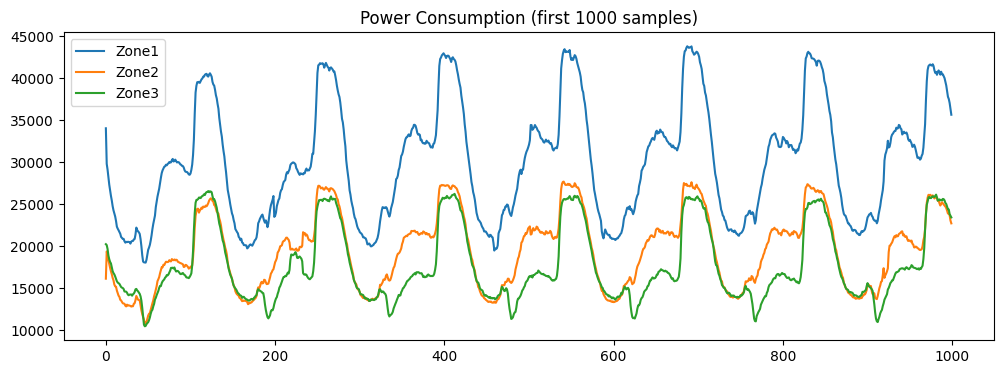

In [7]:
# Analyse de la consommation par zone
plt.figure(figsize=(12,4))

plt.plot(df["PowerConsumption_Zone1"][:1000], label="Zone1")
plt.plot(df["PowerConsumption_Zone2"][:1000], label="Zone2")
plt.plot(df["PowerConsumption_Zone3"][:1000], label="Zone3")

plt.legend()
plt.title("Power Consumption (first 1000 samples)")
plt.show()

#1- On peut parfaitement constater les trois zones ont un comportement similaire:
  * L'augmentation dans une zone entraine l'augmentation dans les autres zones , donc elles sont corrélées
  * On note néanmoins une consommation plus importante au niveau de la zone 1; Cela peut etre du a une population plus abondante ou une activites industrielle plus accrue dans cette zone.



#2- On note des cycles repetitifs dans les 3 zones:
  * On a principalement identifier 7 cycles, ce qui correspond probablement a une semaine. Donc un cycle represente une consommation journalière
  * Donc ici analyser la consommation en une semaine reviendrait a analyser 7 cycles minimum, et pour analyser un cycle il faudra 144 observations


<Axes: xlabel='hour'>

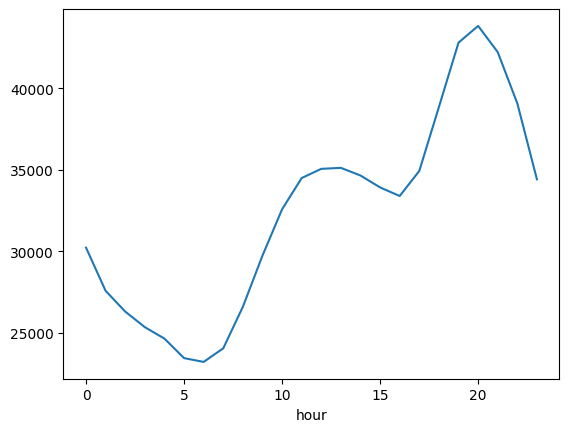

In [53]:
# Analyse de la saisonnalité journaliere
df['Datetime'] = pd.to_datetime(df['Datetime'])
df["hour"] = df["Datetime"].dt.hour

df.groupby("hour")["PowerConsumption_Zone1"].mean().plot()



1.   la consommation décroît entre 0 et 5h, et elle est mionimale entre 4h et 5h( habitants endormi, pas d'activités industrielles)
2.   Elle commence a croître a partir de 7h-10h( debut des activités)
3. le pic maximale est atteint a 20h( retour a la maison, utilisant des appareil électronique etc
4. Et une rechutte apres ( preparation pour le couché, moins de consommations sur les appareils électriques

Ceci nous emmène à comprendre que la variable temporelle joue un role tres important dans la prediction de la consommation électrique; Elle pourrait nettement ameliorer les prediction si elle est pris en compte, sans elle le modele ne pourra probablement pas capter ces differents pics et changement.



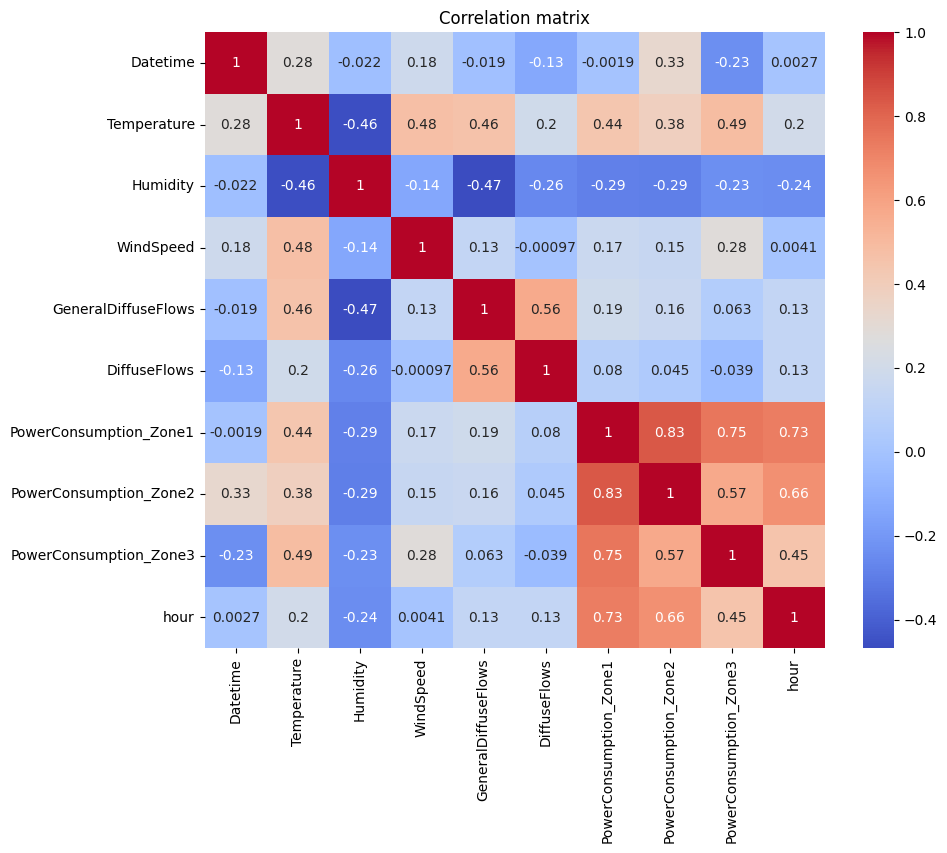

In [9]:
# Analyse de la correlation
import seaborn as sns
corr = df.corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()



1.   Les Consommations des trois zones sont corrélées ( > 0.5). cela pourrait s'expliquer par le fait que les 3 zones sont soumises aux meme conditions météorologiques; les activites humaines s'effectuent aux memes horaires
2.   Cela signifie aussi que la consommation d'une zone peut aider à  predire les autres.
3. la variable hour est correlee a la consommation et  la plus important parmis les variables explicatives(0.73,0.66,0.45).
4. la temperature a une correlation moderee. cela peut expliquer qu'elle influence la consommation via le chauffage/climatisation
5. L'humilité a une correlation negative mais pas tres significative(-0.29); donc l'augmentation de l'humidité entraine une diminution de la consommation électrique



## Construction du baseline: Regression lineaire

In [83]:
# Selection des variables
features = ["Temperature", "Humidity", "WindSpeed", "hour"] #,"PowerConsumption_Zone2","PowerConsumption_Zone3"
target = "PowerConsumption_Zone1"

X = df[features]
y = df[target]


In [84]:
split = int(len(df) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

In [85]:
# Entrainement
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [86]:
# prediction
y_pred = model.predict(X_test)

In [87]:
# Evaluation
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

mae = mean_absolute_error(y_test, y_pred)
mse= mean_squared_error(y_test, y_pred)
rmse=np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print('RMSE',rmse)
print("R2:", r2)

MAE: 3449.91495384309
RMSE 4273.187337838883
R2: 0.5197771367990034




1.   R2=0.519, Le modele explique environ 52 % de la variation de la consommation electrique. c'est un modele acceptable mais pas excellent car une grande partie de la dynamique de la consommation n'est pas capturée par le modèle.
2.  le Mae= 3449 signifie que l'erreur moyenne est d'environ 3400 kwh . Etant donne que la consommation moyenne est de 32000, le modele fait environ 11% d'erreur sur les prediction( 3449/32000).
3.  Le RMSE est encore plus significatif (> au MAE). Le RMSE penalise plus les gosses erreurs, donc cela veut dire qu'il existe des erreus importantes probablement lors des pics ou des transitions jour -nuit



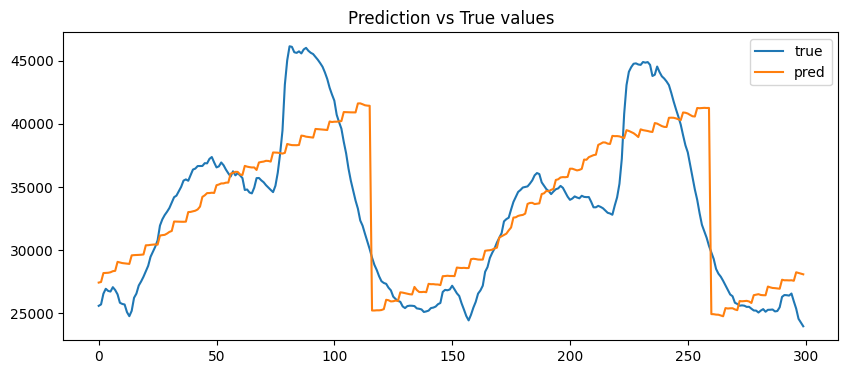

In [15]:
#Visualisation
plt.figure(figsize=(10,4))

plt.plot(y_test.values[:300], label="true")
plt.plot(y_pred[:300], label="pred")

plt.legend()
plt.title("Prediction vs True values")
plt.show()

Nous pouvns effectivement constater que le modele suit la tendance generale mais ne capture pas tres bien les pics de consommation et les transitions au cours d'une journee.

## Construction du modele lstm

Le but est de predire la prochaine consommation electrique # 1 en considérant les observations d'une journee entière ie 144 points(car 10 min -> 6*24= 144 points/jour)


In [16]:
df.head()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3,hour
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386,0
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434,0
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373,0
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711,0
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964,0


In [26]:
# 2) Création des features temporelles simples

df["dayofweek"] = df["Datetime"].dt.dayofweek

# Encodage cyclique de l’heure
df["hour_sin"] = np.sin(2*np.pi*df["hour"]/24)
df["hour_cos"] = np.cos(2*np.pi*df["hour"]/24)

# 3) Choix des features explicatives multivarié
features = [
    "PowerConsumption_Zone1","Temperature", "Humidity", "WindSpeed",
    "hour_sin", "hour_cos",
    "PowerConsumption_Zone2", "PowerConsumption_Zone3"
]

target = "PowerConsumption_Zone1"

# 4) Construire X_raw et y_raw
X_raw = df[features].values.astype(np.float32)
y_raw = df[[target]].values.astype(np.float32)

# 5) Split temporel train/val/test
N = len(df)
train_end = int(0.70 * N)
val_end   = int(0.85 * N)

X_train_raw, X_val_raw, X_test_raw = X_raw[:train_end], X_raw[train_end:val_end], X_raw[val_end:]
y_train_raw, y_val_raw, y_test_raw = y_raw[:train_end], y_raw[train_end:val_end], y_raw[val_end:]

# 6) Normalisation
x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = x_scaler.fit_transform(X_train_raw)
X_val_scaled   = x_scaler.transform(X_val_raw)
X_test_scaled  = x_scaler.transform(X_test_raw)

y_train_scaled = y_scaler.fit_transform(y_train_raw)
y_val_scaled   = y_scaler.transform(y_val_raw)
y_test_scaled  = y_scaler.transform(y_test_raw)

# 7) Creation des séquences
def make_sequences(X, y, window=144, horizon=1):
    """
    X: (T, n_features)
    y: (T, 1)
    window: nb pas observés (ex: 144 = 24h si pas=10min)
    horizon: combien de pas dans le futur (1 = prochaine mesure)
    """
    Xs, ys = [], []
    T = len(X)
    for i in range(T - window - horizon + 1):
        Xs.append(X[i:i+window])
        ys.append(y[i+window+horizon-1])
    return np.array(Xs), np.array(ys)

# 8) Choix de la fenêtre
WINDOW  = 144
HORIZON = 1

X_train, y_train = make_sequences(X_train_scaled, y_train_scaled, window=WINDOW, horizon=HORIZON)
X_val, y_val     = make_sequences(X_val_scaled,   y_val_scaled,   window=WINDOW, horizon=HORIZON)
X_test, y_test   = make_sequences(X_test_scaled,  y_test_scaled,  window=WINDOW, horizon=HORIZON)

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val  :", X_val.shape,   "y_val  :", y_val.shape)
print("X_test :", X_test.shape,  "y_test :", y_test.shape)
print("n_features =", X_train.shape[2])

X_train: (36547, 144, 8) y_train: (36547, 1)
X_val  : (7718, 144, 8) y_val  : (7718, 1)
X_test : (7719, 144, 8) y_test : (7719, 1)
n_features = 8


In [41]:
# construction du modele lstm
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

n_features = X_train.shape[2]

model = Sequential([
    LSTM(32, input_shape=(WINDOW, n_features),kernel_regularizer=l2(1e-4)),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="mse"
)

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 32)             │         5,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,337 (24.75 KB)

 Trainable params: 6,337 (24.75 KB)

 Non-trainable params: 0 (0.00 B)

In [42]:
# Entrainement
from tensorflow.keras.callbacks import ReduceLROnPlateau
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)
lr_sched=ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-5
    )

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stop,lr_sched],
    verbose=1
)

Epoch 1/20
572/572 ━━━━━━━━━━━━━━━━━━━━ 42s 66ms/step - loss: 0.7452 - val_loss: 0.1292 - learning_rate: 1.0000e-04
Epoch 2/20
572/572 ━━━━━━━━━━━━━━━━━━━━ 36s 63ms/step - loss: 0.1328 - val_loss: 0.0834 - learning_rate: 1.0000e-04
Epoch 3/20
572/572 ━━━━━━━━━━━━━━━━━━━━ 44s 69ms/step - loss: 0.0850 - val_loss: 0.0509 - learning_rate: 1.0000e-04
Epoch 4/20
572/572 ━━━━━━━━━━━━━━━━━━━━ 36s 63ms/step - loss: 0.0639 - val_loss: 0.0355 - learning_rate: 1.0000e-04
Epoch 5/20
572/572 ━━━━━━━━━━━━━━━━━━━━ 37s 65ms/step - loss: 0.0510 - val_loss: 0.0267 - learning_rate: 1.0000e-04
Epoch 6/20
572/572 ━━━━━━━━━━━━━━━━━━━━ 43s 69ms/step - loss: 0.0436 - val_loss: 0.0227 - learning_rate: 1.0000e-04
Epoch 7/20
572/572 ━━━━━━━━━━━━━━━━━━━━ 37s 65ms/step - loss: 0.0375 - val_loss: 0.0200 - learning_rate: 1.0000e-04
Epoch 8/20
572/572 ━━━━━━━━━━━━━━━━━━━━ 41s 65ms/step - loss: 0.0345 - val_loss: 0.0168 - learning_rate: 1.0000e-04
Epoch 9/20
572/572 ━━━━━━━━━━━━━━━━━━━━ 39s 68ms/step - loss: 0.0315 - v

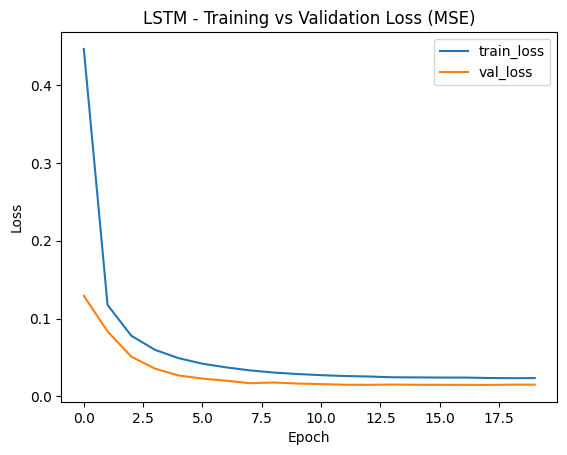

In [43]:
plt.figure()
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.title("LSTM - Training vs Validation Loss (MSE)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [44]:

# 1) Prédire sur le test
y_pred_test = model.predict(X_test, verbose=0)

# 2) Revenir à l'échelle originale
y_test_inv = y_scaler.inverse_transform(y_test)
y_pred_inv = y_scaler.inverse_transform(y_pred_test)

In [45]:
mae  = mean_absolute_error(y_test_inv, y_pred_inv)
rmse = np.sqrt(mean_squared_error(y_test_inv, y_pred_inv))
r2   = r2_score(y_test_inv, y_pred_inv)

print("LSTM TEST MAE :", mae)
print("LSTM TEST RMSE:", rmse)
print("LSTM TEST R2  :", r2)

LSTM TEST MAE : 929.181884765625
LSTM TEST RMSE: 1104.0883682930457
LSTM TEST R2  : 0.966839611530304


Le LSTM explique a 96% la variation de la consommation, ce qui est plutot excellent et nettement meilleur que le baseline. le modele fait des erreur moyennes d'environ  929kwh, ce qui sous entend une marge d'erreur de 2% (929/32000).

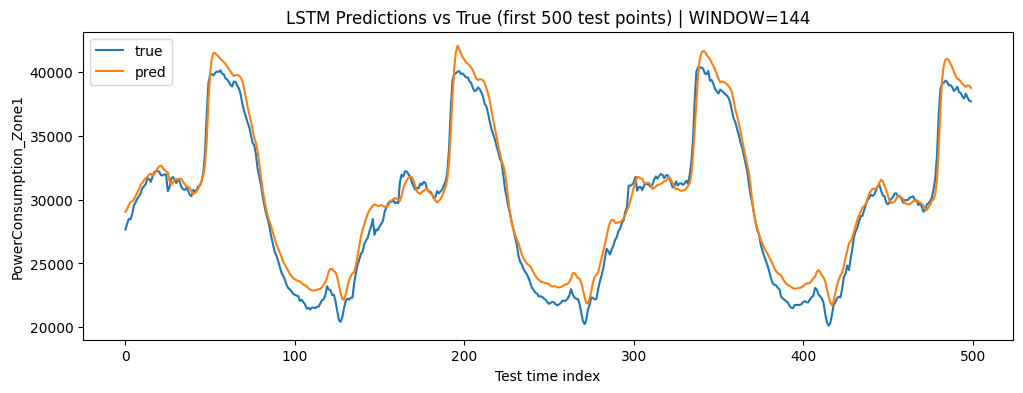

In [46]:
import matplotlib.pyplot as plt

n_plot = min(500, len(y_test_inv))

plt.figure(figsize=(12,4))
plt.plot(y_test_inv[:n_plot], label="true")
plt.plot(y_pred_inv[:n_plot], label="pred")
plt.title(f"LSTM Predictions vs True (first {n_plot} test points) | WINDOW={WINDOW}")
plt.xlabel("Test time index")
plt.ylabel("PowerConsumption_Zone1")
plt.legend()
plt.show()

La tendance generale est bien prise en compte ainsi que les pics et les différentes transitions. Le LSTM convient dont parfaitement a notre jeu de données sur la prediction de la consommation électrique dans la zone 1.